# 1-board: sample-timing

Find from which duty each crest sample reads the drive honestly, on a 2S rail and on a 1S rail, and where in the window the samples land, so the window floors the board registry carries are graded against the board they belong to and against the lower rail.

## Purpose

The board samples the shunt and the taps once per PWM period, at fixed instants around the counter's crest, and a sample counts only when the drive window is at least `i_window_min_ticks` or `v_window_min_ticks` wide, the floors the board registry carries. Below those floors the current limit, calibration and identification are blind. The floors were set on a 2S rail. On a 1S rail the bridge's gate drive and its switching edges are slower, so a window that is wide enough at 7.4 V may not be at 3.7 V. The op-amp and the ADC run from the 3.3 V regulator, which still holds at 3.7 V, so the amplifier's own settle should not change.

On a resistor the current inside a window is the same at every duty, so a rung whose crest sample reads less than a wider rung reads early, and the lowest honest rung is the floor. The bursts draw the current and the terminals inside one period at a resolution the crest sample never has, which says where the edges and the settle are, and whether they move with the rail.

## Procedure

A duty ladder on the bare load at 7.4 V, 3 to 40 % and the 100 % control, both directions, in slow decay and again in fast, each rung 150 ms with a rest between. Then `osc-lab burst` at four duties, three captures each, with the shunt and both taps interleaved. Then the slow ladder and the bursts again at 3.7 V.

1. The board on the DPS, the bare load on the terminals, the adapter on the bus at 3 Mbps. No meter.
2. `capture.py`. It raises the current limit for the ladders and puts the saved one back. The servo resets when the DPS steps down to the 1S level and comes back at its saved limit, so the script sets the wider limit again after the step.

## Data

- `ladder-slow/`, `ladder-fast/`, `ladder-slow-1s/`: `sweep.csv` and `meta.json`, one row per control tick, one segment per rung, the first segment the torque-off rest.
- `bursts/burst-<k>.csv`, `bursts-1s/burst-<k>.csv`: the free-running ADC through PWM periods around a duty step, `code` the raw sample, the meta fields on the first row. The shunt converts every second sample, the two taps alternate between them.

### The ladders

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import boards, bursts as bu, results, tel
from oscnb.display import show

# one colour per rail throughout: blue is the 2S level, orange the 1S level
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
BOARD = boards.BOARDS[boards.DEFAULT]
CAPTURE = (Path("../../../telemetry") / BOARD.key / "sample-timing" / "capture-1").resolve()
# the two rails, each with its slow ladder, its burst folder and its colour
RAILS = {"7.4 V": ("ladder-slow", "bursts", BLUE), "3.7 V": ("ladder-slow-1s", "bursts-1s", ORANGE)}
ARR = BOARD.pwm_arr          # 1200 ticks from trough to crest; a window is drive_ticks either side of the crest
print(BOARD.key, "from", results.rel(CAPTURE))

dev-v006-2A-D from telemetry/dev-v006-2A-D/sample-timing/capture-1


ladder-slow: 28 rungs, rail at rest 7.37 V, gaps none
ladder-fast: 28 rungs, rail at rest 7.37 V, gaps none
ladder-slow-1s: 28 rungs, rail at rest 3.69 V, gaps none


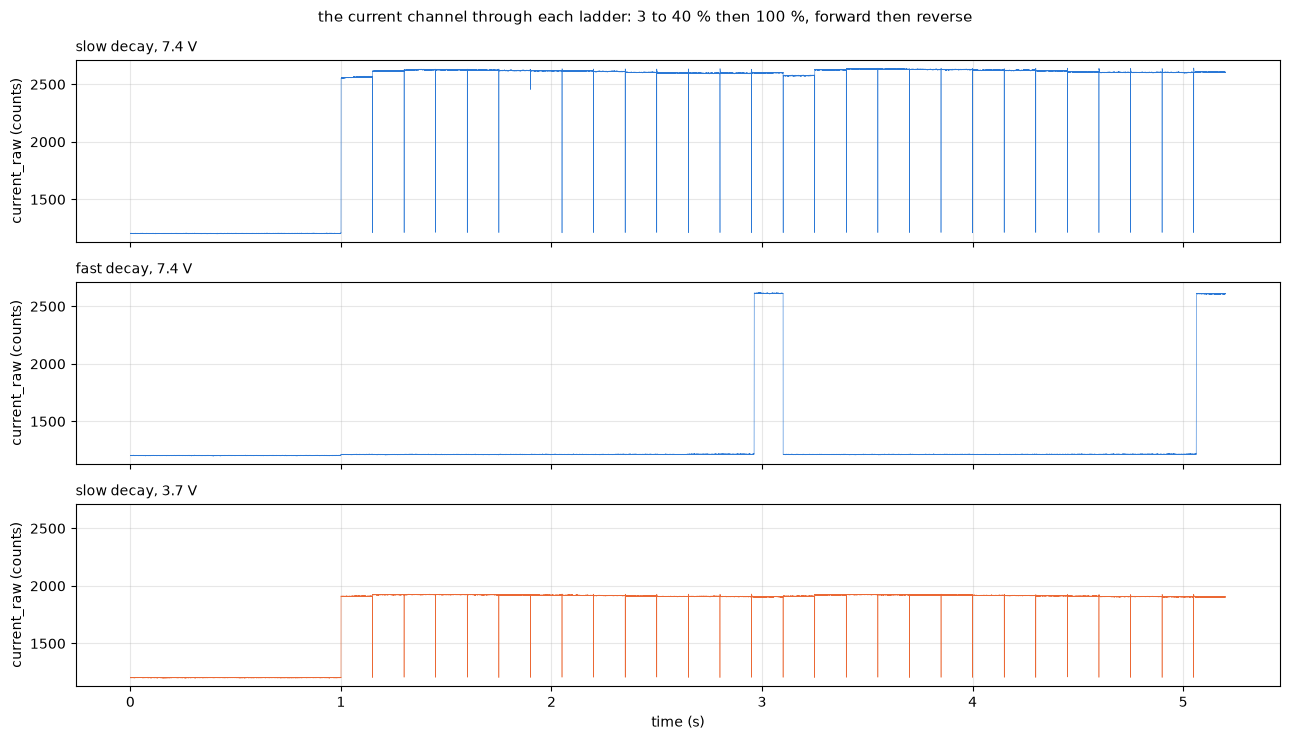

In [2]:
# every ladder as recorded: the current channel against time, the rest then every rung
ladders = {name: tel.load(CAPTURE / name, BOARD) for name in ("ladder-slow", "ladder-fast", "ladder-slow-1s")}
labels = {"ladder-slow": "slow decay, 7.4 V", "ladder-fast": "fast decay, 7.4 V", "ladder-slow-1s": "slow decay, 3.7 V"}
fig, ax = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True, sharey=True)
for a, (name, (df, meta)) in zip(ax, ladders.items()):
    color = ORANGE if name.endswith("1s") else BLUE
    t_run = np.arange(len(df)) / meta.get("tick_hz", 20_000)      # `tick` restarts at every segment, so time runs over the rows
    a.plot(t_run, df["current_raw"], lw=0.4, color=color)
    a.set_ylabel("current_raw (counts)"); a.set_title(labels[name], loc="left", fontsize=10); a.grid(alpha=0.3)
    print(f"{name}: {df['seg'].max()} rungs, rail at rest {BOARD.rail_v(tel.baseline(df)['vbus_raw'].mean()):.2f} V, gaps {tel.gaps(df).to_dict() or 'none'}")
ax[-1].set_xlabel("time (s)")
fig.suptitle("the current channel through each ladder: 3 to 40 % then 100 %, forward then reverse", fontsize=11)
plt.tight_layout(); plt.show()

The current channel through each ladder, the rest first, then the fourteen rungs forward and the fourteen reverse. The 3.7 V ladder is orange and the 7.4 V ladders blue, the rail colours every later figure keeps. Under slow decay every rung at 7.4 V sits near the same level, which is the resistor's current at the rail, and the 100 % rung is the switching-free control at the end of each direction. At 3.7 V the level is half. Under fast decay the crest sample reads nothing at any rung up to 40 %: under fast decay the drive window sits at the trough and the trough scan reads it, which this row does not carry. The fast ladder is left at that below.

## Method

Each rung's settled mean of the current channel over its rest zero, and of the tap difference, with the applied window in ticks from `duty_counts`. The sample instants are fixed by the scan. The crest trigger fires at the crest, the shunt's aperture closes 31 ticks after it, the high-side tap's 83 ticks after it, and the low-side tap converts on an injected trigger that closes 37 ticks before the crest. The rail tap is slot 5 of the same scan and closes 291 ticks after the crest, so it reads the rail inside the drive window only when the window reaches 291 ticks either side of the crest, 24 % duty. Below that it reads the rail between pulses, which has recovered, and a ratio to the 100 % rung corrected by the rail tap over-corrects. The first figure below shows that. So the rungs are graded in two ranges.

- The 3 to 15 % rungs, where the window is short and the rail tap is outside it, against the mean of the 7 to 15 % rungs. For the current that is the channel itself. For the terminal difference it is the ratio of the difference to the current, the load's resistance as the board sees it, which does not depend on the rail. A rung that reads early reads low, so the floors are found walking down from 15 %: the floor is the lowest rung with every rung above it, up to 15 %, inside the band.
- The 20 to 40 % rungs against the 100 % rung of the same direction, corrected by the rail tap once it is inside the window. This says whether a switched rung and the switching-free control agree.

The bursts fold each sample onto the PWM period by the counter value at the step, so every sample has a time in ticks from the crest. The shunt's ON edge is the first point past half its plateau, the OFF edge the last, and the settle is the time from the commanded window start to the first point inside 1 % of the plateau that stays there. The same at both rails.

### Rungs against the 100 % rung through the rail tap

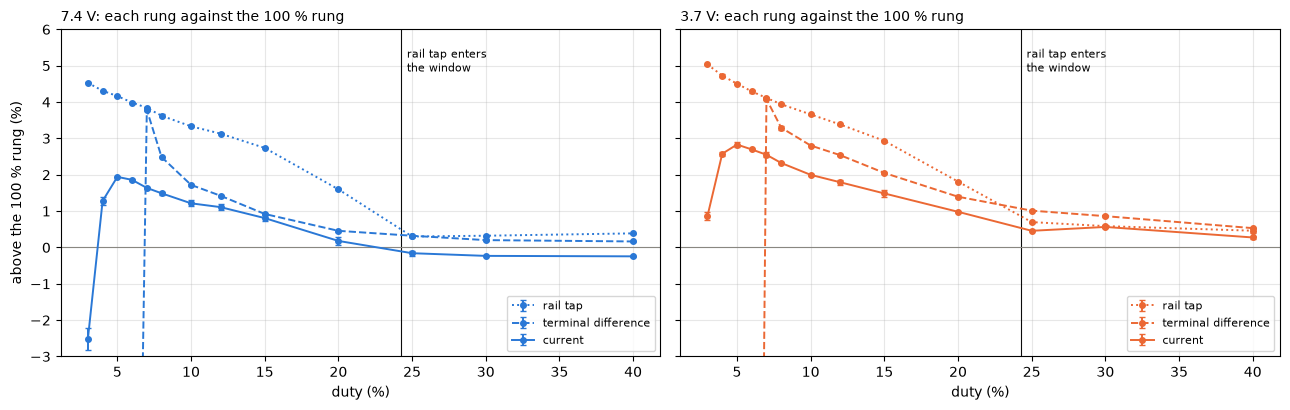

In [3]:
def rung_table(df):
    # one row per rung and direction: the settled means of the raw columns, the window in ticks, the window_valid share
    b = tel.baseline(df)
    zero = b["current_raw"].median()                      # the amplifier's zero from the torque-off rest
    r = tel.rungs(df)
    wv = [tel.settled(g)["window_valid"].mean() for _, g in df[df["seg"] > 0].groupby("seg")]
    r["window_valid"] = wv
    r["ticks"] = r["duty_ticks"]                          # drive_ticks: the window's half-width in timer ticks
    r["duty_pct"] = BOARD.duty_pct_of_ticks(r["ticks"])
    r["i"] = r["current_raw"] - zero                      # counts of current over the zero
    r["v"] = (r["vmotor_a"] - r["vmotor_b"]).abs()         # counts of terminal difference, bias free
    r["control"] = r["cmd_duty_q15"].abs() >= 32000       # the 100 % rung
    return r

R = {rail: rung_table(ladders[name][0]) for rail, (name, _, _) in RAILS.items()}

def versus_control(r):
    # each rung as a ratio to the 100 % rung of its direction: the current, the terminal difference and the rail tap itself
    out = []
    for sgn, g in r.groupby("dir"):
        ref = g[g["control"]].iloc[0]
        out.append(g.assign(i_ratio=g["i"] / ref["i"], v_ratio=g["v"] / ref["v"], rail_ratio=g["vbus_raw"] / ref["vbus_raw"]))
    return pd.concat(out)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, (rail, (name, _, color)) in zip(ax, RAILS.items()):
    g = versus_control(R[rail]); g = g[~g["control"]]
    m = g.groupby("duty_pct")[["i_ratio", "v_ratio", "rail_ratio"]].agg(["mean", "min", "max"])
    for col, ls, lab in (("rail_ratio", ":", "rail tap"), ("v_ratio", "--", "terminal difference"), ("i_ratio", "-", "current")):
        a.errorbar(m.index, (m[(col, "mean")] - 1) * 100, yerr=[(m[(col, "mean")] - m[(col, "min")]) * 100, (m[(col, "max")] - m[(col, "mean")]) * 100],
                   fmt="o", ms=4, lw=1.4, ls=ls, color=color, capsize=2, label=lab)
    a.axvline(291 / 12, color=INK, lw=0.8); a.text(291 / 12 + 0.4, a.get_ylim()[1] if a.get_ylim()[1] < 6 else 5.5, "rail tap enters\nthe window", fontsize=8, va="top")
    a.axhline(0, color=MUTED, lw=0.8)
    a.set_xlabel("duty (%)"); a.set_title(f"{rail}: each rung against the 100 % rung", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=8, loc="lower right")
ax[0].set_ylabel("above the 100 % rung (%)")
ax[0].set_ylim(-3, 6)
plt.tight_layout(); plt.show()

Left 7.4 V, right 3.7 V, the same axes. Each rung's current, terminal difference and rail tap as a percentage over the 100 % rung of its direction, the point the mean of the two directions and the whisker their spread. Above the line at 24 % all three move together, since all three read inside the same window and see the same rail. Below it the rail tap climbs away from the other two. It reads the rail between pulses, which the DPS has pulled back up, while the current and the terminal difference read the rail inside the pulse.

### From which duty each channel reads the drive

published: current from 64 ticks (5.3 %), terminals from 93 ticks (7.8 %); 12 ticks = 1 %


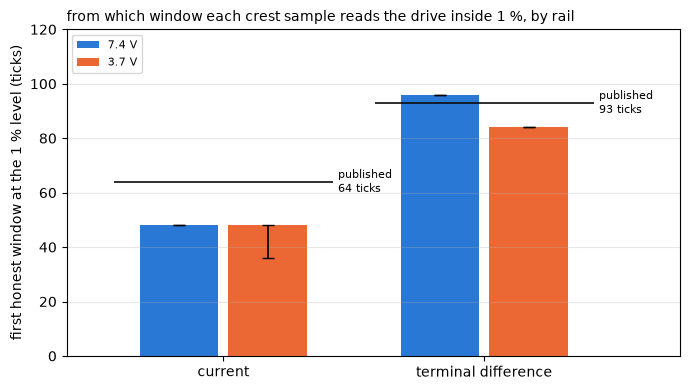

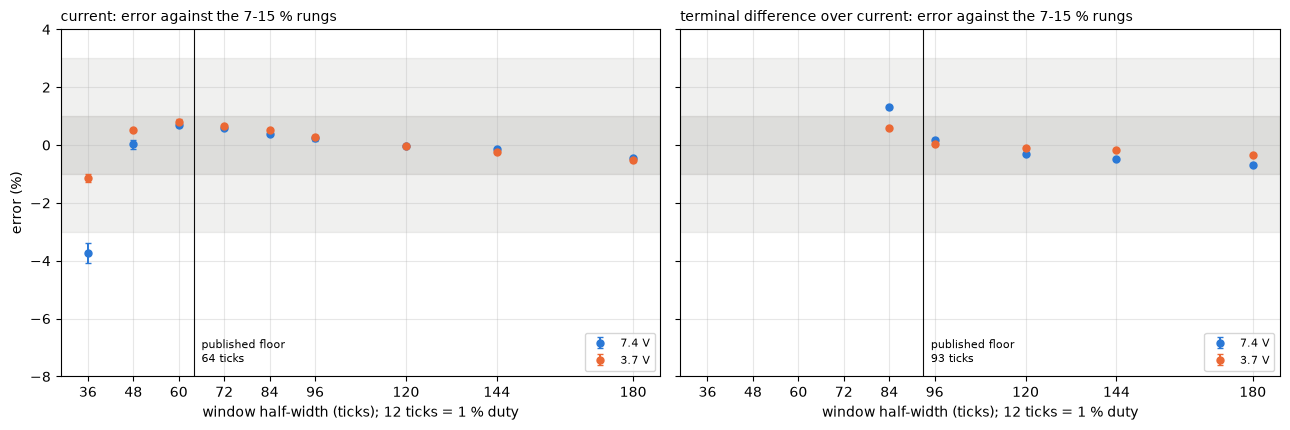

7.4 V: the 25 to 40 % rungs read -0.55 % (sd 0.09) on the current and -0.11 % (sd 0.11) on the terminal difference against the 100 % rung through the rail tap, over the rungs and both directions
3.7 V: the 25 to 40 % rungs read -0.15 % (sd 0.10) on the current and +0.22 % (sd 0.12) on the terminal difference against the 100 % rung through the rail tap, over the rungs and both directions


In [4]:
# the short-window grading: each rung against the mean of the 7 to 15 % rungs, walking down from 15 %
SHORT = (84, 180)     # the reference span in ticks: 7 % to 15 %

def short_errors(r):
    # per direction: the current against the span's mean current; the terminal difference as v / i against the span's mean v / i
    out = []
    for sgn, g in r.groupby("dir"):
        g = g[~g["control"]].sort_values("ticks")
        ref = g[(g["ticks"] >= SHORT[0]) & (g["ticks"] <= SHORT[1])]
        ratio = g["v"] / g["i"]
        out.append(g.assign(i_err=(g["i"] / ref["i"].mean() - 1) * 100, v_err=(ratio / (ref["v"] / ref["i"]).mean() - 1) * 100))
    return pd.concat(out)

def floor_ticks(g, col, tol):
    # walk down from the top of the short range: the floor is the lowest rung with every rung above it inside the band
    g = g[g["ticks"] <= SHORT[1]].sort_values("ticks", ascending=False)
    low = np.nan
    for ticks, ok in zip(g["ticks"], g[col].abs() <= tol):
        if not ok:
            break
        low = ticks
    return low

E = {rail: short_errors(R[rail]) for rail in RAILS}
rows = []
for rail, e in E.items():
    for sgn, g in e.groupby("dir"):
        rows.append({"rail": rail, "dir": sgn, "i_1pct": floor_ticks(g, "i_err", 1), "i_3pct": floor_ticks(g, "i_err", 3),
                     "v_1pct": floor_ticks(g, "v_err", 1), "v_3pct": floor_ticks(g, "v_err", 3)})
F = pd.DataFrame(rows)
print(f"published: current from {BOARD.i_window_min_ticks} ticks ({BOARD.i_floor_pct:.1f} %), terminals from {BOARD.v_window_min_ticks} ticks ({BOARD.v_floor_pct:.1f} %); 12 ticks = 1 %")

# the headline: the first honest window per channel and rail at the 1 % level, the bar the worse direction, the whisker down to the better one
fig, ax = plt.subplots(figsize=(7, 4))
chans = (("i_1pct", "current", BOARD.i_window_min_ticks), ("v_1pct", "terminal difference", BOARD.v_window_min_ticks))
w = 0.3
for k, (rail, (_, _, color)) in enumerate(RAILS.items()):
    f = F[F["rail"] == rail]
    top = [f[col].max() for col, _, _ in chans]; low = [f[col].min() for col, _, _ in chans]
    ax.bar(np.arange(2) + (k - 0.5) * (w + 0.04), top, w, color=color, label=rail, yerr=[np.subtract(top, low), np.zeros(2)], capsize=4, error_kw={"lw": 1.2, "color": INK})
for j, (_, name, floor) in enumerate(chans):
    ax.hlines(floor, j - 0.42, j + 0.42, color=INK, lw=1.2); ax.text(j + 0.44, floor, f"published\n{floor} ticks", fontsize=8, va="center")
ax.set_xticks([0, 1], [name for _, name, _ in chans]); ax.set_ylabel("first honest window at the 1 % level (ticks)")
ax.set_title("from which window each crest sample reads the drive inside 1 %, by rail", loc="left", fontsize=10)
ax.set_ylim(0, 120); ax.set_xlim(-0.6, 1.75); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for a, col, name, floor in ((ax[0], "i_err", "current", BOARD.i_window_min_ticks), (ax[1], "v_err", "terminal difference over current", BOARD.v_window_min_ticks)):
    for rail, (_, _, color) in RAILS.items():
        g = E[rail]; g = g[g["ticks"] <= SHORT[1]]
        m = g.groupby("ticks")[col].agg(["mean", "min", "max"])
        a.errorbar(m.index, m["mean"], yerr=[m["mean"] - m["min"], m["max"] - m["mean"]], fmt="o", ms=5, lw=1.4, color=color, capsize=2, label=rail)
    a.axhspan(-3, 3, color=MUTED, alpha=0.12); a.axhspan(-1, 1, color=MUTED, alpha=0.18)
    a.axvline(floor, color=INK, lw=0.8); a.text(floor + 2, -7.5, f"published floor\n{floor} ticks", fontsize=8)
    a.set_xlabel("window half-width (ticks); 12 ticks = 1 % duty"); a.set_title(f"{name}: error against the 7-15 % rungs", loc="left", fontsize=10)
    a.set_xticks([36, 48, 60, 72, 84, 96, 120, 144, 180]); a.grid(alpha=0.3); a.legend(fontsize=8, loc="lower right")
ax[0].set_ylabel("error (%)"); ax[0].set_ylim(-8, 4)
plt.tight_layout(); plt.show()

# the long-window check: the 20-40 % rungs against the 100 % rung through the rail tap
rows = []
for rail in RAILS:
    g = versus_control(R[rail]); g = g[(g["ticks"] >= 300) & ~g["control"]]
    rows.append({"rail": rail, "current": ((g["i_ratio"] / g["rail_ratio"] - 1) * 100).mean(), "current_spread": ((g["i_ratio"] / g["rail_ratio"] - 1) * 100).std(),
                 "terminal": ((g["v_ratio"] / g["rail_ratio"] - 1) * 100).mean(), "terminal_spread": ((g["v_ratio"] / g["rail_ratio"] - 1) * 100).std()})
LONG = pd.DataFrame(rows).set_index("rail")
for rail in RAILS:
    L = LONG.loc[rail]
    print(f"{rail}: the 25 to 40 % rungs read {L['current']:+.2f} % (sd {L['current_spread']:.2f}) on the current and {L['terminal']:+.2f} % (sd {L['terminal_spread']:.2f}) "
          f"on the terminal difference against the 100 % rung through the rail tap, over the rungs and both directions")

The first figure is the answer: for each channel, the narrowest window from which the crest sample reads inside 1 % of the wider rungs, a bar per rail. The bar is the worse of the two directions and the whisker reaches down to the better one, so a bar with no whisker is the two directions agreeing. The black line is the floor the registry carries. The second figure is where the bars come from. Left the current, right the terminal difference over the current, each rung's error against the 7 to 15 % rungs, 7.4 V in blue and 3.7 V in orange, the point the mean of the two directions and the whisker their spread. The bands are 1 % and 3 %, the vertical line the published floor. A channel is honest from the width where its points enter the band and stay. The printed lines under it are the long-window check, the 25 to 40 % rungs against the 100 % control through the rail tap.

### Inside one period

7.4 V 24 bursts at [-38, -25, -15, -10, 10, 15, 25, 38] % duty
3.7 V 24 bursts at [-38, -25, -15, -10, 10, 15, 25, 38] % duty


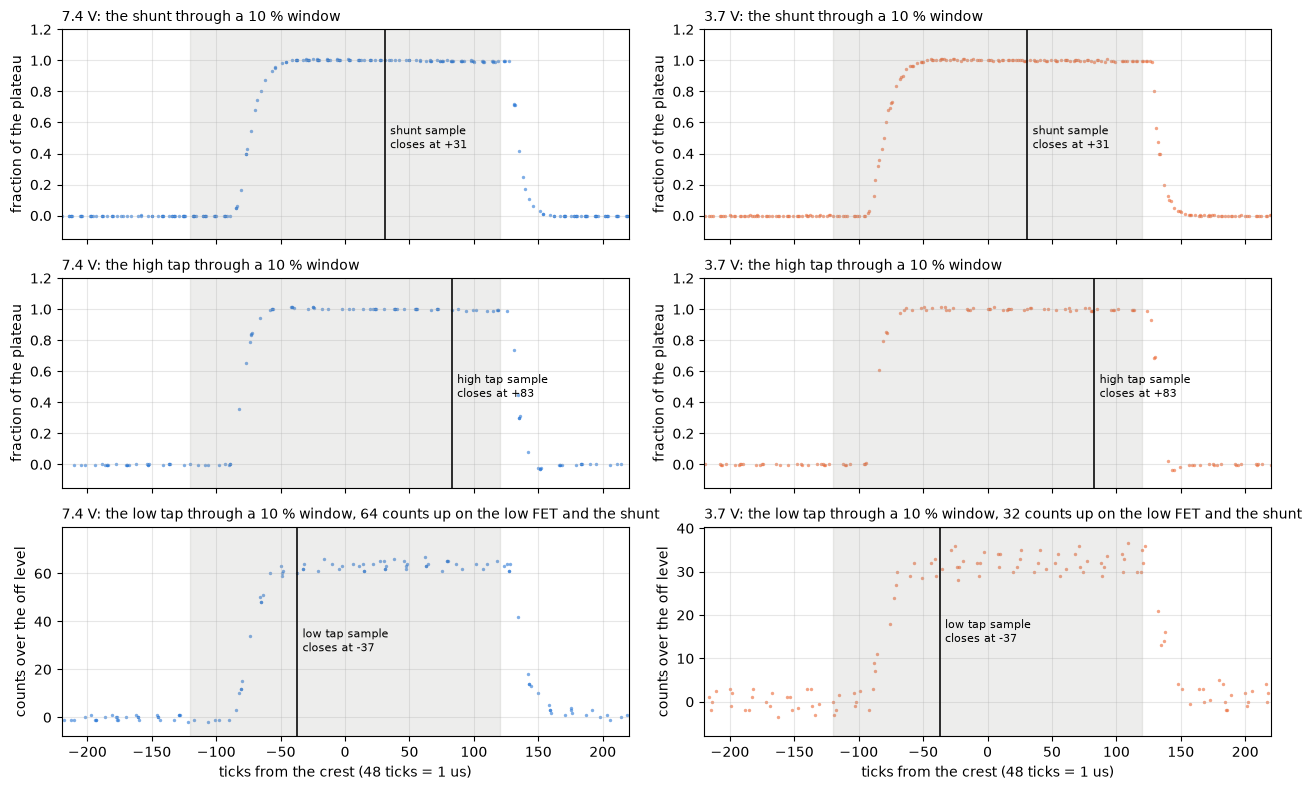

In [5]:
CAPS = {rail: bu.load(CAPTURE / name) for rail, (_, name, _) in RAILS.items()}
for rail, caps in CAPS.items():
    print(rail, len(caps), "bursts at", sorted({round(bu.meta(c)["step_q15"] * 100 / 32768) for c in caps}), "% duty")
INSTANTS = {"low tap": -37, "shunt": 31, "high tap": 83}     # ticks from the crest at which each crest sample closes

def role_streams(cap):
    # the streams by role: the shunt, the high-side tap (the driven terminal) and the low-side tap, by the step's sign
    fwd = bu.meta(cap)["step_q15"] > 0
    return {"shunt": "sh", "high tap": "ta" if fwd else "tb", "low tap": "tb" if fwd else "ta"}

def fold_norm(cap, role):
    # one stream folded onto the period, as a fraction of its plateau: 0 at its level outside the window, 1 on the plateau
    m = bu.meta(cap); half = int(BOARD.drive_ticks(m["step_q15"]))
    t, y, _ = bu.fold(cap, ARR, role_streams(cap)[role])
    off = np.median(y[(t > half + 150) | (t < -half - 150)])
    plat = np.median(y[(t > -half + 100) & (t < half - 30)])
    return t, (y - off) / (plat - off), half, off, plat

# the narrowest burst, 10 % duty, at both rails: all six captures of each rail pooled
fig, ax = plt.subplots(3, 2, figsize=(13, 8), sharex=True)
for col, (rail, (_, _, color)) in enumerate(RAILS.items()):
    caps = [c for c in CAPS[rail] if abs(bu.meta(c)["step_q15"]) == min(abs(bu.meta(c)["step_q15"]) for c in CAPS[rail])]
    for row, role in enumerate(("shunt", "high tap", "low tap")):
        a = ax[row, col]
        tt, yy, rises = [], [], []
        for c in caps:
            t, y, half, off, plat = fold_norm(c, role); tt.append(t); rises.append(plat - off)
            # the low tap rises only by the current through the low FET and the shunt, tens of counts,
            # so it is drawn in counts: as a fraction of so small a plateau the two counts of fuzz look like noise
            yy.append(y * (plat - off) if role == "low tap" else y)
        tt, yy = np.concatenate(tt), np.concatenate(yy)
        a.scatter(tt, yy, s=6, color=color, alpha=0.6, lw=0)
        a.axvspan(-half, half, color=MUTED, alpha=0.15)
        a.axvline(INSTANTS[role], color=INK, lw=1.2)
        if role == "low tap":
            a.set_ylim(-8, 1.25 * np.median(rises)); a.set_ylabel("counts over the off level")
            a.text(INSTANTS[role] + 4, 0.5 * np.median(rises), f"{role} sample\ncloses at {INSTANTS[role]:+d}", fontsize=8, va="center")
            a.set_title(f"{rail}: the low tap through a {2 * half / 24:.0f} % window, {np.median(rises):.0f} counts up on the low FET and the shunt", loc="left", fontsize=10)
        else:
            a.set_ylim(-0.15, 1.2); a.set_ylabel("fraction of the plateau")
            a.text(INSTANTS[role] + 4, 0.5, f"{role} sample\ncloses at {INSTANTS[role]:+d}", fontsize=8, va="center")
            a.set_title(f"{rail}: the {role} through a {2 * half / 24:.0f} % window", loc="left", fontsize=10)
        a.grid(alpha=0.3)
ax[-1, 0].set_xlabel("ticks from the crest (48 ticks = 1 us)"); ax[-1, 1].set_xlabel("ticks from the crest (48 ticks = 1 us)")
ax[0, 0].set_xlim(-220, 220)
plt.tight_layout(); plt.show()

The 10 % window, 120 ticks either side of the crest, at 7.4 V on the left and 3.7 V on the right. Each row is one stream folded onto the period from six captures, as a fraction of its plateau. The grey band is the commanded window, the vertical line the instant the board's own sample of that stream closes. The shunt starts rising well after the window's commanded start and falls shortly after its commanded end. The high-side tap is the driven terminal, read at +83. The low-side tap is drawn in counts, since it only rises by the current through the low FET and the shunt, about 62 counts at 7.4 V and 32 at 3.7 V, and the two counts of fuzz every stream carries under drive would look like noise against so small a plateau. It is read at -37, which at this width is close to the edge.

### The edges and the settle at each rail

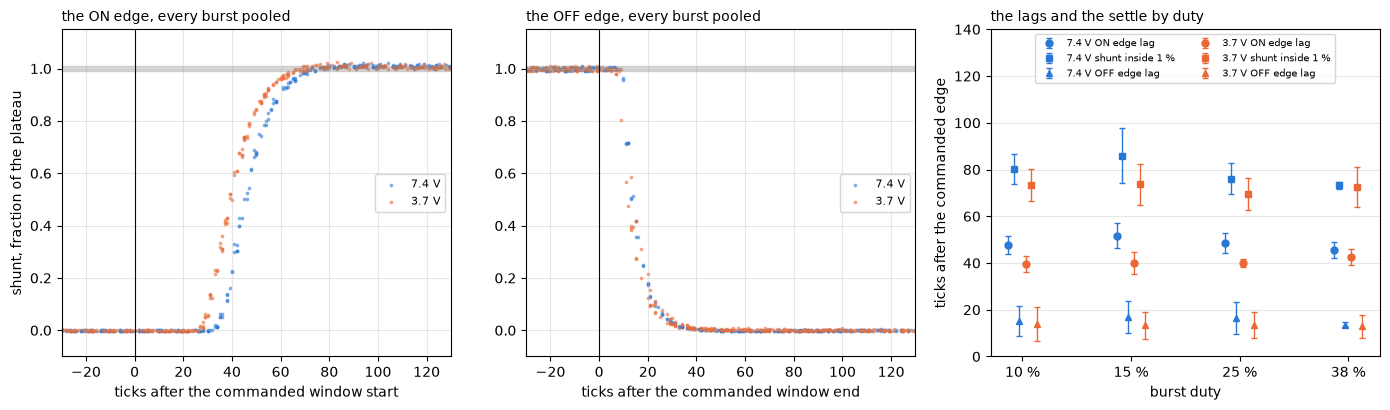

In [6]:
def edges(cap):
    # the shunt's ON and OFF edges as half-plateau crossings, and its settle, in ticks, from a 2-tick profile of the fold
    t, y, half, off, plat = fold_norm(cap, "shunt")
    x, p = bu.profile(t, y, -ARR, ARR, 2)
    up = x[p > 0.5]
    on, offe = up[0], up[-1]
    inside = np.flatnonzero((x > on) & (x < half))
    ok = np.abs(p - 1) <= 0.01
    settled = [i for i in inside if ok[i] and ok[i + 1] and ok[i + 2]]
    settle = x[settled[0]] + half if settled else np.nan           # from the commanded window start
    # the high-side tap sees the bridge's edge without the amplifier: its own half-plateau crossing
    th, yh, _, _, _ = fold_norm(cap, "high tap")
    xh, ph = bu.profile(th, yh, -ARR, ARR, 2)
    tap_on = xh[ph > 0.5][0]
    return {"pct": abs(bu.meta(cap)["step_q15"]) * 100 / 32768, "half": half, "on_lag": on + half, "tap_on_lag": tap_on + half, "off_lag": offe - half,
            "settle": settle, "at_shunt": float(np.interp(INSTANTS["shunt"], x, p)), "at_high": float(np.interp(INSTANTS["high tap"], xh, ph))}

ED = pd.concat([pd.DataFrame([dict(rail=rail, **edges(c)) for c in caps]) for rail, caps in CAPS.items()])

# the ON edge and the OFF edge, every burst of a rail pooled, against the commanded edges
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for rail, (_, _, color) in RAILS.items():
    on_t, on_y, off_t, off_y = [], [], [], []
    for c in CAPS[rail]:
        t, y, half, _, _ = fold_norm(c, "shunt")
        on_t.append(t + half); on_y.append(y); off_t.append(t - half); off_y.append(y)
    on_t, on_y, off_t, off_y = map(np.concatenate, (on_t, on_y, off_t, off_y))
    ax[0].scatter(on_t, on_y, s=7, color=color, alpha=0.6, lw=0, label=rail)
    ax[1].scatter(off_t, off_y, s=7, color=color, alpha=0.6, lw=0, label=rail)
for a, name in ((ax[0], "after the commanded window start"), (ax[1], "after the commanded window end")):
    a.axvline(0, color=INK, lw=0.8); a.axhspan(0.99, 1.01, color=MUTED, alpha=0.3)
    a.set_xlim(-30, 130); a.set_ylim(-0.1, 1.15); a.set_xlabel(f"ticks {name}"); a.grid(alpha=0.3); a.legend(fontsize=8, loc="center right")
ax[0].set_ylabel("shunt, fraction of the plateau"); ax[0].set_title("the ON edge, every burst pooled", loc="left", fontsize=10)
ax[1].set_title("the OFF edge, every burst pooled", loc="left", fontsize=10)
# the lags and the settle per duty, one point a duty, the whisker the spread over the six captures
x = np.arange(len(sorted(ED["pct"].unique())))
for k, (rail, (_, _, color)) in enumerate(RAILS.items()):
    g = ED[ED["rail"] == rail].groupby("pct")
    for j, (col, mk, lab) in enumerate((("on_lag", "o", "ON edge lag"), ("settle", "s", "shunt inside 1 %"), ("off_lag", "^", "OFF edge lag"))):
        m, s = g[col].mean(), g[col].std()
        ax[2].errorbar(x + (k - 0.5) * 0.16 + (j - 1) * 0.05, m, yerr=s, fmt=mk, ms=5, color=color, capsize=2, lw=1, label=f"{rail} {lab}")
ax[2].set_xticks(x, [f"{p:.0f} %" for p in sorted(ED["pct"].unique())]); ax[2].set_xlabel("burst duty"); ax[2].set_ylabel("ticks after the commanded edge")
ax[2].set_title("the lags and the settle by duty", loc="left", fontsize=10); ax[2].grid(alpha=0.3, axis="y"); ax[2].legend(fontsize=7, ncol=2, loc="upper center")
ax[2].set_ylim(0, 140)
plt.tight_layout(); plt.show()

Left, the shunt's rise against the commanded window start, every burst of a rail on top of each other. Middle, its fall against the commanded end. Right, the ON lag, the settle and the OFF lag per burst duty, the point the mean of the six captures and the whisker their standard deviation. The result file carries the lags and the settle pooled per rail, with the high-side tap's own ON crossing beside the shunt's.

## Results

The current channel reads the drive honestly from a 48-tick window (4 % duty) at 7.4 V and from 36 to 48 ticks (3 to 4 %) at 3.7 V. At 7.4 V the 36-tick (3 %) rung reads 3.4 to 4.1 % low and the 48-tick (4 %) rung sits within 0.2 % of the 60 to 96-tick (5 to 8 %) rungs, in both directions. At 3.7 V the 36-tick (3 %) rung reads 1.0 to 1.3 % low, at the edge of the 1 % band, and the 48-tick (4 %) rung within 0.6 %. The published current floor of 64 ticks, 5.3 % duty, holds at both rails with a rung of margin at 7.4 V and two at 3.7 V. The crest shunt sample sits on the plateau to within 0.3 % in every burst from 10 % up at both rails. Over the 60 to 180-tick (5 to 15 %) rungs the current falls by about 1.2 % at both rails as the window lengthens, and over the 25 to 40 % rungs it reads 0.5 % under the 100 % control at 7.4 V and 0.15 % under at 3.7 V once the rail tap is inside the window. The resistor's current in the window is the rail over the load, so the fall with window length most likely is the rail sagging inside the pulse by the time the sample closes, which the terminal difference follows.

The terminal difference over the current, the load as the board sees it, holds within 0.5 % from 96 ticks (8 %) up to the 100 % rung at both rails. The 84-tick (7 %) rung reads 1.3 % high at 7.4 V and 0.6 % high at 3.7 V, and the 72-tick (6 %) rung collapses, 24 % low at 7.4 V and 41 % low at 3.7 V. So the terminal floor at the 1 % level is 96 ticks (8 %) at 7.4 V and 84 ticks (7 %) at 3.7 V, and 84 ticks (7 %) at the 3 % level at both. The published terminal floor of 93 ticks, 7.8 % duty, is inside the band at both rails, with the next rung down failing at 7.4 V and passing at 3.7 V. The 84-tick (7 %) excess is the low-side tap. It closes 37 ticks before the crest, which at that width is a few ticks after the bridge's ON edge, so it reads the low side before it has risen and the difference reads high.

The bursts put the ON edge and the OFF edge where the ladder floors say they are. The shunt crosses half its plateau 48 ticks after the commanded window start at 7.4 V and 40 ticks at 3.7 V, standard deviation 3 to 5 ticks over the 24 captures of each rail. The high-side tap, which sees the bridge's edge without the amplifier, crosses at 42 and 36 ticks. The OFF edge crosses 13 to 16 ticks after the commanded end at both rails. The window is about 32 ticks, 0.7 us, shorter than commanded at 7.4 V and 27 at 3.7 V. The shunt is inside 1 % of its plateau 79 ticks after the commanded start at 7.4 V and 72 at 3.7 V, spread 7 to 8 ticks, which is 31 ticks after its half crossing at both. The 10 to 90 % rise of both the shunt and the tap is 32 to 36 ticks at both rails, the same within the spread.

So the lower rail does not slow the edges in this capture. The ON edge comes 6 to 8 ticks, about 0.15 us, earlier at 3.7 V on both the tap and the shunt, and the settle follows it. The most likely reason is that the bridge's output slews at about the same rate at both rails, so it crosses half of a smaller swing sooner. The current floor is a rung lower at 3.7 V for the same reason. At 36 ticks (3 %) the shunt sample closes 67 ticks after the commanded start, which is 27 ticks after the half crossing at 3.7 V and 19 at 7.4 V.

Under fast decay the crest sample sees no drive at any rung up to 40 %: the current channel reads 8 to 10 counts over its zero and the taps sit at the bias node. Under fast decay the drive window sits at the trough and the trough scan reads it, which the raw row of this capture does not carry, so the fast ladder grades nothing here and the 100 % rung is its only drive.

The result file carries the floors per rail at the 1 % and 3 % levels, in percent duty with the two directions as the bounds, the published floors, and per rail the ON lag of the shunt and of the tap, the OFF lag and the settle, each the median over the 24 bursts with its range.

In [7]:
def floor_q(rail, col):
    f = F[F["rail"] == rail][col]
    return results.quantity(f.max() / 12, lo=f.min() / 12, hi=f.max() / 12, unit="% duty")

def edge_q(rail, col):
    e = ED[ED["rail"] == rail][col]
    return results.quantity(e.median(), lo=e.min(), hi=e.max(), unit="ticks")

key = {"7.4 V": "7v4", "3.7 V": "3v7"}
q = {}
for rail in RAILS:
    k = key[rail]
    q[f"i_floor_1pct_{k}"] = floor_q(rail, "i_1pct"); q[f"i_floor_3pct_{k}"] = floor_q(rail, "i_3pct")
    q[f"v_floor_1pct_{k}"] = floor_q(rail, "v_1pct"); q[f"v_floor_3pct_{k}"] = floor_q(rail, "v_3pct")
    q[f"on_edge_lag_{k}"] = edge_q(rail, "on_lag"); q[f"tap_on_edge_lag_{k}"] = edge_q(rail, "tap_on_lag")
    q[f"off_edge_lag_{k}"] = edge_q(rail, "off_lag"); q[f"shunt_settle_{k}"] = edge_q(rail, "settle")
results.write("1-board", "sample-timing", CAPTURE, pair=BOARD.key,
              notes="duty ladders on the bare load at 7.4 V and 3.7 V, floors walked down from 15 % against the 7-15 % rungs. "
                    "bursts folded on the PWM period, lags from the commanded edges, the settle from the commanded window start to 1 % of the plateau",
              published_i_floor=results.quantity(BOARD.i_floor_pct, unit="% duty"),
              published_v_floor=results.quantity(BOARD.v_floor_pct, unit="% duty"), **q)

PosixPath('stages/1-board/sample-timing/results/dev-v006-2A-D.json')

## Limitations

- A resistor has no inductance, so the current steps on at the edge and settles with the amplifier. A winding's current ramps through the window instead, which is easier on the sample and harder on the reading's meaning. The lags and the settle carry over, the floors are for the step.
- The rail inside the pulse is not measured on its own. The rail tap closes 291 ticks after the crest, so it reads inside the window only from 25 % duty, and below that the rungs are graded against each other over the 7 to 15 % span. The current's 1.2 % fall with window length over that span is read as the rail sagging in the pulse, which is a hypothesis the terminal difference supports and a meter on the rail would settle.
- One load per rail. The 3.7 V step is half the 7.4 V step on the same 5 ohm load, so the rail and the step size change together. The high-side tap separates the bridge's edge from the amplifier, but a second load at one rail would separate the step size from the rail for the amplifier's own settle.
- The ladder's rungs are 12 ticks apart below 10 %, so a floor is known to a rung. The terminal floor at 7.4 V sits between 84 and 96 ticks (7 and 8 %), and the published 93 is inside that gap.
- The fast-decay ladder grades nothing. The row carries the crest samples and the drive is at the trough. A fast ladder with the trough columns in the row is a separate capture.
- The ON and OFF edges are read as half-plateau crossings on a 2-tick profile of samples 8 ticks apart per capture, so a single capture's edge is good to a few ticks and the per-rail means to about a tick and a half.
- The DPS is the supply. The servo resets when the DPS steps down to the 1S level and returns at its saved current limit, so the script sets the wider limit again after the step. A pack does not step.

## Open questions

- Whether the ON edge's earlier crossing at 3.7 V is the bridge's slew. The tap's edge moved by the same amount as the shunt's, which points at the bridge, and a fixed slew rate crossing half of a smaller swing would give it. A fold of the tap's edge in volts rather than as a fraction of its plateau, at three rails, would say whether the slope is the same.
- Whether the terminal difference over the current dips at 180 to 240 ticks (15 to 20 %). It reads 0.4 % under the rungs either side at both rails, with the low-side tap rising with window length while the high side falls. It is under the 1 % band and left as an observation.
- Both taps read about 42 counts higher on the 100 % rung than on the 40 % rung at 7.4 V, and about 19 at 3.7 V, while their difference stays. A common shift of that size on a switching-free drive looks like a ground or bias shift with the mean current, which the terminal-chain experiment can see with its meter on a tap.
- The fall of the current with window length, 1.2 % from 60 to 180 ticks (5 to 15 %), is read as the rail sagging inside the pulse. A burst with the rail tap in its frame would show the rail inside the window directly.

## Conclusion

The window floors the registry carries for this board hold at 3.7 V as well as at 7.4 V, and no margin is needed on the lower rail. The current floor of 64 ticks (5.3 % duty) is inside 1 % at both rails, with the first honest rung at 48 ticks (4 %) at 7.4 V and at 36 to 48 ticks (3 to 4 %) at 3.7 V. The terminal floor of 93 ticks (7.8 %) is inside 1 % at both rails, with the first honest rung at 96 ticks (8 %) at 7.4 V and 84 (7 %) at 3.7 V. The lower rail reads honestly from a narrower window on both channels, by one rung on the current and one on the terminals.

The edges go the other way from what a slower gate drive would give. The ON edge crosses 6 to 8 ticks earlier at 3.7 V on the shunt and on the tap alike, the OFF edge is the same at both rails, and the rise times are the same. The most likely explanation is a bridge output that slews at the same rate at both rails and so reaches half of a smaller swing sooner. The amplifier's settle after the edge, 31 ticks to 1 %, is the same at both rails, as it should be from a 3.3 V regulator that holds.

Later experiments should take three things from this run.

- The rail tap reads inside the drive window only from 25 % duty. A ratio to the rail tap below that compares a pulse's rail with the recovered one, and over-corrects by a few percent at 7.4 V. Grade short windows against each other, or against the terminal difference, not against the rail tap.
- Under fast decay the crest samples carry no drive. A fast-decay capture needs the trough columns in its row.
- The servo resets when the DPS steps down. Any volatile setting made before a step down has to be made again after it.